In [5]:
import csv
import math
from pathlib import Path

import matplotlib.pyplot as plt
%matplotlib inline

# V2 is the selected implementation. Change to "v1" or "v3" if needed.
VERSION = "v2"
LOG_SCALE = True
MESSAGE_NAMES = {
    1: "C1: Neighbour request",
    2: "C2: Neighbour response",
    3: "C3: Congestion report",
    4: "C4: Base reply",
    5: "TERMINATE",
    6: "DISABLE",
    7: "READY",
    8: "TERMINATED",
    9: "QUERY_GRANT (V1)",
    10: "QUERY_DONE (V1)",
}

In [6]:
def load_data(folder, suite):
    filename = f"{suite}_messages.csv"
    with (folder / filename).open(encoding="utf-8-sig", newline="") as file:
        records = list(csv.DictReader(file))
        
    selected = [r for r in records if r["suite"] == suite and r["version"] == VERSION]
    expected_tags = set(range(1, 11 if VERSION == "v1" else 9))
    shapes = {(int(r["rows"]), int(r["cols"])) for r in selected}
    
    if VERSION not in {"v1", "v2", "v3"} or len(shapes) != 30:
        raise ValueError(f"Choose v1/v2/v3; exactly 30 {suite} sizes are required.")
        
    if suite == "line":
        if any(rows != 1 and cols != 1 for rows, cols in shapes):
            raise ValueError("Each line topology must have one row or one column.")
        if len({rows * cols for rows, cols in shapes}) != 30:
            raise ValueError("The 30 line instances must have 30 different station counts.")
            
    if len({r["predefined_period"] for r in selected}) != 1:
        raise ValueError("The predefined period must be the same for all selected runs.")
        
    seen = set()
    for r in selected:
        key = (int(r["rows"]), int(r["cols"]), int(r["tag"]))
        if key in seen or int(r["tag"]) not in expected_tags:
            raise ValueError("Duplicate grid/tag or unexpected message type. Use one repetition.")
        seen.add(key)
        if int(r["stations"]) != key[0] * key[1] or int(r["processes"]) != key[0] * key[1] + 1:
            raise ValueError("Station/process count does not match the grid.")
        if r["sent"] != r["received"] or r["send_bytes"] != r["receive_bytes"]:
            raise ValueError("Unbalanced message counts or payload bytes.")
        for field in ["mean_send_api_us", "mean_receive_api_us"]:
            if r[field] and (not math.isfinite(float(r[field])) or float(r[field]) < 0):
                raise ValueError(f"Invalid timing in {field}.")
                
    expected = {(rows, cols, tag) for rows, cols in shapes for tag in expected_tags}
    if seen != expected:
        raise ValueError("At least one grid/message record is missing.")
    if len({r["replicate"] for r in selected}) != 1:
        raise ValueError("Use a single repetition for these plots.")
        
    return sorted(selected, key=lambda r: (int(r["tag"]), int(r["stations"]), int(r["rows"]), int(r["cols"])))

def label_peak(ax, stations, values, color, suite):
    valid = [i for i, value in enumerate(values) if math.isfinite(value)]
    if not valid:
        return
    index = max(valid, key=lambda i: values[i])
    x, y = stations[index], values[index]
    
    ax.scatter([x], [y], s=32, color=color, edgecolors="white", linewidths=0.7, zorder=4)
    
    if suite == "mesh":
        offset = -10 if x > (stations[0] + stations[-1]) / 2 else 10
        ax.annotate(f"Max: {y:.2f} us\n{x} stations", xy=(x, y), xytext=(offset, 12),
                    textcoords="offset points", ha="right" if offset < 0 else "left",
                    va="bottom", fontsize=8, color=color, zorder=5,
                    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, alpha=0.9),
                    arrowprops=dict(arrowstyle="-", color=color, linewidth=0.7))
    else:
        is_send = color == "#4477AA"
        name = "Send" if is_send else "Receive"
        ax.text(0.02 if is_send else 0.98, 0.97, f"{name} max: {y:.2f} us\n{x} stations",
                transform=ax.transAxes, ha="left" if is_send else "right", va="top",
                fontsize=8, color=color, zorder=5,
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, alpha=0.9))

def plot_messages(records, tags, title, output, filename, suite):
    fig, axes = plt.subplots(2 if len(tags) > 2 else 1, 2, figsize=(12, 7.5 if len(tags) > 2 else 4.5), squeeze=False)
    send_field, receive_field = "mean_send_api_us", "mean_receive_api_us"
    ylabel = "Mean MPI call time (us)"
    
    for ax, tag in zip(axes.flat, tags):
        rows = [r for r in records if int(r["tag"]) == tag]
        stations = [int(r["stations"]) for r in rows]
        send = [float(r[send_field]) if r[send_field] else math.nan for r in rows]
        receive = [float(r[receive_field]) if r[receive_field] else math.nan for r in rows]
        
        ax.plot(stations, send, "o-", color="#4477AA", label="Send", markersize=3, linewidth=1.3)
        ax.plot(stations, receive, "s-", color="#EE7733", label="Receive", markersize=3, linewidth=1.3)
        
        finite_values = [v for v in send + receive if math.isfinite(v)]
        use_log = LOG_SCALE and finite_values and min(finite_values) > 0
        if use_log:
            ax.set_yscale("log")
        else:
            ax.set_ylim(bottom=0)
            
        ax.set_title(MESSAGE_NAMES[tag])
        ax.set_ylabel(ylabel + (", log scale" if use_log else ""))
        
        if suite == "mesh":
            ax.set_xlabel("Charging stations (rows x cols)")
            ax.set_xticks([4, 10, 20, 30, 40, 45])
        else:
            ax.set_xlabel("Charging stations in line")
            ax.set_xticks([2, 5, 10, 15, 20, 25, 31])
            
        ax.set_axisbelow(True)
        ax.grid(axis="both", which="major", alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False, fontsize=8, loc="lower right", ncol=2)
        ax.margins(y=0.35)
        
        label_peak(ax, stations, send, "#4477AA", suite)
        label_peak(ax, stations, receive, "#EE7733", suite)
        
    fig.suptitle(f"Task 3{'a' if suite=='mesh' else 'b'} - {VERSION.upper()} {suite.capitalize()}: {title}", fontsize=16)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    
    if output:
        fig.savefig(output / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

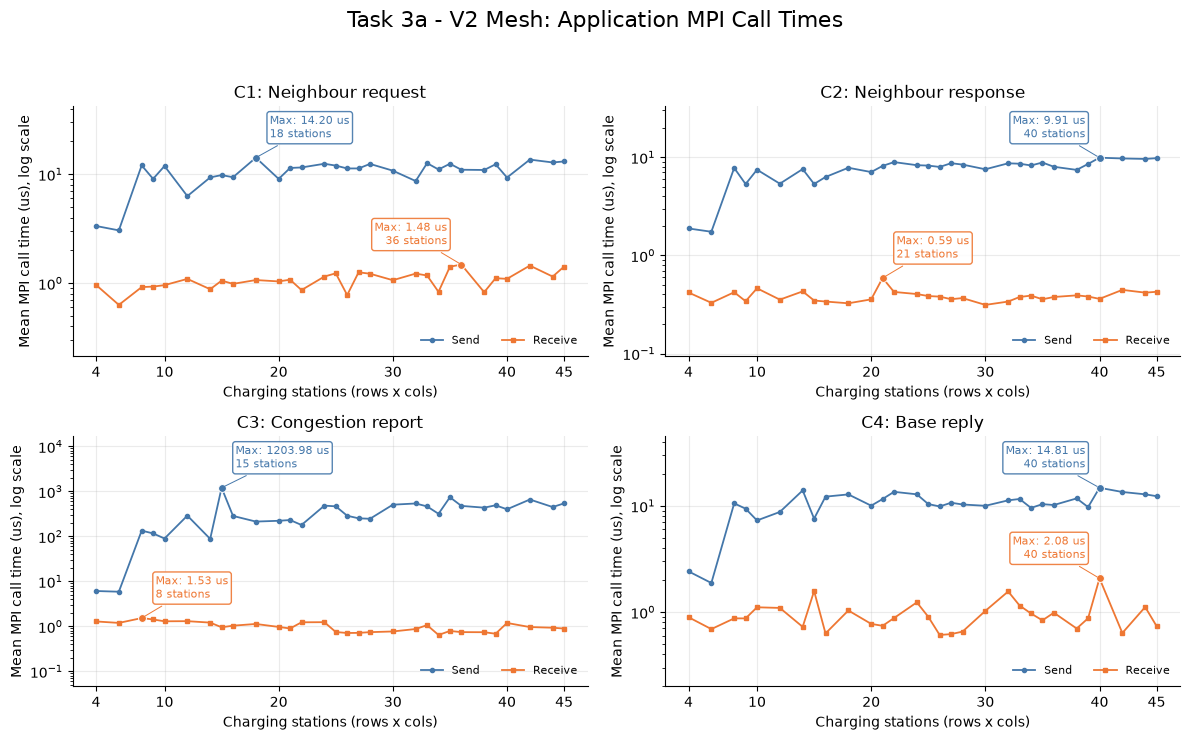

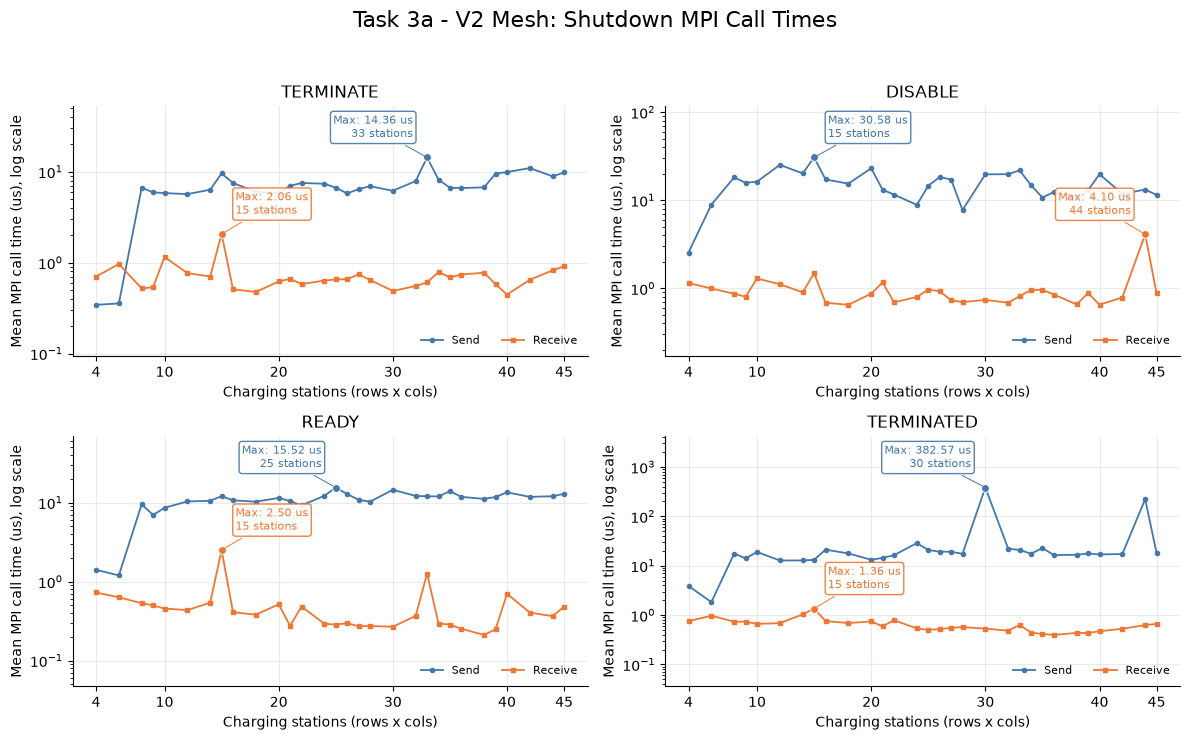

Generated V2 Mesh graphs.


In [7]:
folder = Path.cwd()
output = folder / f"graph_{VERSION}"
output.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.titlesize": 12})

records_mesh = load_data(folder, "mesh")
plot_messages(records_mesh, [1, 2, 3, 4], "Application MPI Call Times", output, "mesh_01_application_call_times.png", "mesh")
plot_messages(records_mesh, [5, 6, 7, 8], "Shutdown MPI Call Times", output, "mesh_02_shutdown_call_times.png", "mesh")

if VERSION == "v1":
    plot_messages(records_mesh, [9, 10], "Scheduling MPI Call Times", output, "mesh_03_scheduling_call_times.png", "mesh")
    
print(f"Generated {VERSION.upper()} Mesh graphs.")

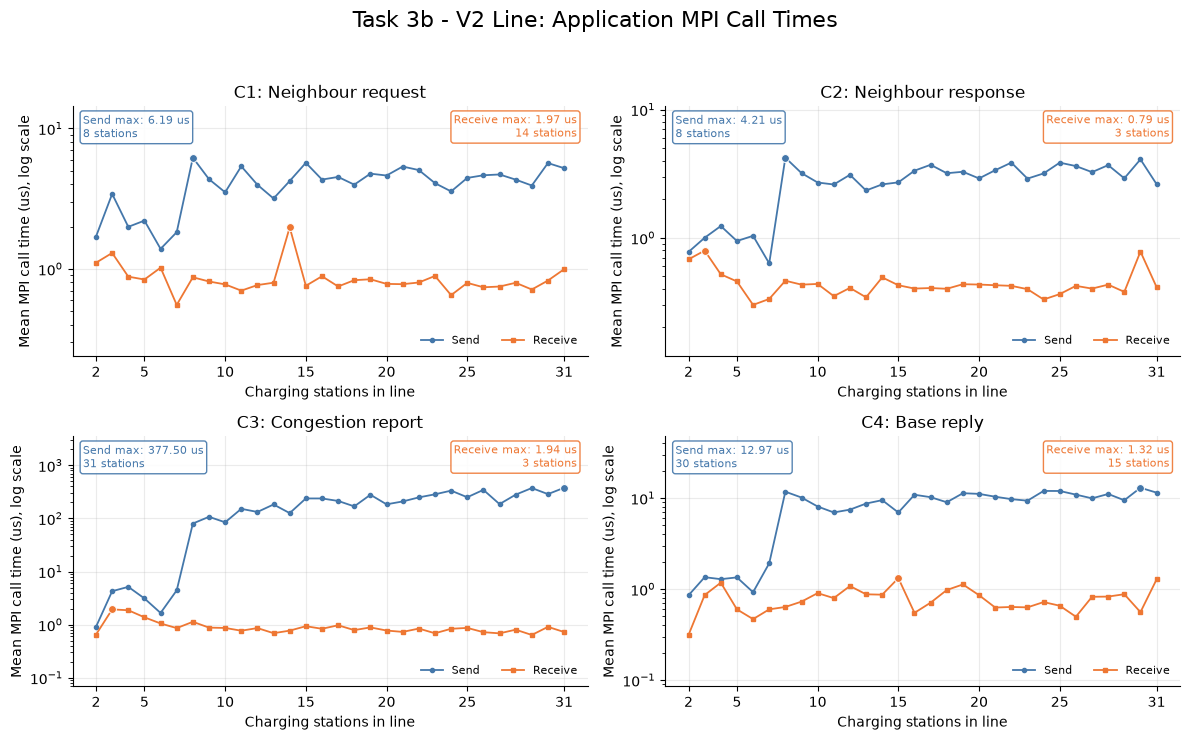

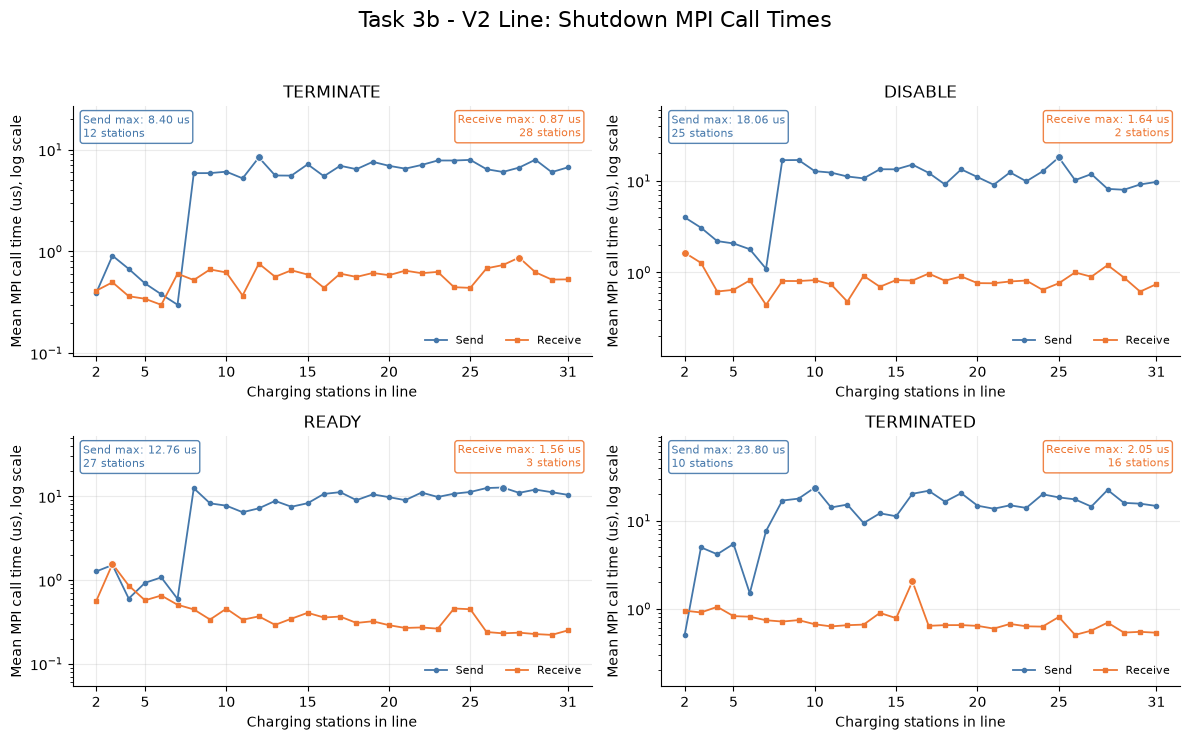

Generated V2 Line graphs.


In [8]:
records_line = load_data(folder, "line")
plot_messages(records_line, [1, 2, 3, 4], "Application MPI Call Times", output, "line_01_application_call_times.png", "line")
plot_messages(records_line, [5, 6, 7, 8], "Shutdown MPI Call Times", output, "line_02_shutdown_call_times.png", "line")

if VERSION == "v1":
    plot_messages(records_line, [9, 10], "Scheduling MPI Call Times", output, "line_03_scheduling_call_times.png", "line")
    
print(f"Generated {VERSION.upper()} Line graphs.")